NAME: ALINA USMAN

ROLL NO:24F-AI-146

PROJECT:HEALTH RISK CLASSIFICATION

In [4]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [5]:
# Load the dataset

df = pd.read_csv('diabetes.csv')

# Display first five rows
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1


In [6]:
# Check number of rows and columns

print("Dataset shape:", df.shape)

Dataset shape: (768, 9)


In [7]:
# Display dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(4), int64(5)
memory usage: 54.1 KB


In [8]:
# Display basic statistical information

df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.677083,72.389323,29.089844,141.753906,32.434635,0.471876,33.240885,0.348958
std,3.369578,30.464161,12.106039,8.890820,89.100847,6.880498,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,102.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,28.000000,102.500000,32.050000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,169.500000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [9]:
# Display column names

print(df.columns)

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')


CHECK MISSING VALUES

In [10]:
# Check missing values

df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


CHECK ZERO VALUES

In [11]:
# Check the number of zero values in each column

zero_values = (df == 0).sum()

print(zero_values)

Pregnancies                 111
Glucose                       0
BloodPressure                 0
SkinThickness                 0
Insulin                       0
BMI                           0
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64


In [12]:
# Replace medically invalid zero values with NaN

columns_with_zero = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

df[columns_with_zero] = df[columns_with_zero].replace(0, np.nan)

# Check missing values again

df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [13]:
# Display the cleaned dataset

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1


In [14]:
# Separate input features and target variable

X = df.drop('Outcome', axis=1)
y = df['Outcome']

print("Features:")
print(X.columns)

print("\nTarget:")
print(y.name)

Features:
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'],
      dtype='object')

Target:
Outcome


In [15]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


In [16]:
# Create StandardScaler

scaler = StandardScaler()

# Fit scaler on training data and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Data normalization completed.")

Data normalization completed.


TRAIN SVM MODEL

In [17]:
# Create SVM model

svm_model = SVC(kernel='rbf', random_state=42)

# Train the model

svm_model.fit(X_train_scaled, y_train)

print("SVM model trained successfully.")

SVM model trained successfully.


In [19]:
# Make predictions using SVM

svm_predictions = svm_model.predict(X_test_scaled)

print(svm_predictions[:10])

[0 0 0 1 0 0 1 1 0 1]


In [20]:
# Calculate SVM evaluation metrics

svm_accuracy = accuracy_score(y_test, svm_predictions)
svm_precision = precision_score(y_test, svm_predictions)
svm_recall = recall_score(y_test, svm_predictions)
svm_f1 = f1_score(y_test, svm_predictions)

print("SVM Results")
print("----------------------")
print("Accuracy :", svm_accuracy)
print("Precision:", svm_precision)
print("Recall   :", svm_recall)
print("F1 Score :", svm_f1)

SVM Results
----------------------
Accuracy : 0.8376623376623377
Precision: 0.7636363636363637
Recall   : 0.7777777777777778
F1 Score : 0.7706422018348624


In [21]:
# Detailed classification report

print("SVM Classification Report")
print(classification_report(y_test, svm_predictions))

SVM Classification Report
              precision    recall  f1-score   support

           0       0.88      0.87      0.87       100
           1       0.76      0.78      0.77        54

    accuracy                           0.84       154
   macro avg       0.82      0.82      0.82       154
weighted avg       0.84      0.84      0.84       154



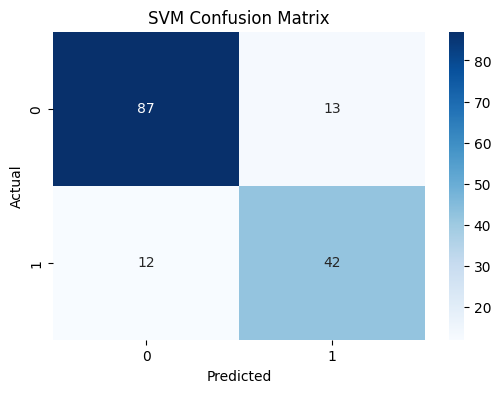

In [22]:
# Create confusion matrix

svm_cm = confusion_matrix(y_test, svm_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('SVM Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

DECISION TREE MODEL

In [23]:
# Create Decision Tree model

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# Train the model

dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [24]:
# Make predictions using Decision Tree

dt_predictions = dt_model.predict(X_test)

print(dt_predictions[:10])

[0 0 0 1 0 0 1 1 0 1]


In [25]:
# Calculate Decision Tree metrics

dt_accuracy = accuracy_score(y_test, dt_predictions)
dt_precision = precision_score(y_test, dt_predictions)
dt_recall = recall_score(y_test, dt_predictions)
dt_f1 = f1_score(y_test, dt_predictions)

print("Decision Tree Results")
print("----------------------")
print("Accuracy :", dt_accuracy)
print("Precision:", dt_precision)
print("Recall   :", dt_recall)
print("F1 Score :", dt_f1)

Decision Tree Results
----------------------
Accuracy : 0.8246753246753247
Precision: 0.7547169811320755
Recall   : 0.7407407407407407
F1 Score : 0.7476635514018691


In [26]:
# Detailed classification report

print("Decision Tree Classification Report")
print(classification_report(y_test, dt_predictions))

Decision Tree Classification Report
              precision    recall  f1-score   support

           0       0.86      0.87      0.87       100
           1       0.75      0.74      0.75        54

    accuracy                           0.82       154
   macro avg       0.81      0.81      0.81       154
weighted avg       0.82      0.82      0.82       154



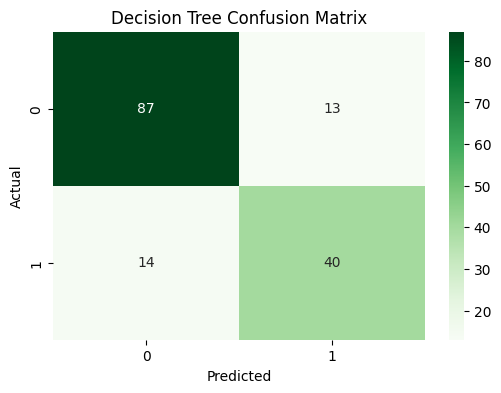

In [27]:
# Create Decision Tree confusion matrix

dt_cm = confusion_matrix(y_test, dt_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [28]:
# Compare both models

results = pd.DataFrame({
    'Model': ['SVM', 'Decision Tree'],
    'Accuracy': [svm_accuracy, dt_accuracy],
    'Precision': [svm_precision, dt_precision],
    'Recall': [svm_recall, dt_recall],
    'F1 Score': [svm_f1, dt_f1]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,SVM,0.837662,0.763636,0.777778,0.770642
1,Decision Tree,0.824675,0.754717,0.740741,0.747664


In [29]:
# Calculate training accuracy

svm_train_predictions = svm_model.predict(X_train_scaled)
dt_train_predictions = dt_model.predict(X_train)

svm_train_accuracy = accuracy_score(y_train, svm_train_predictions)
dt_train_accuracy = accuracy_score(y_train, dt_train_predictions)

print("SVM Training Accuracy:", svm_train_accuracy)
print("SVM Testing Accuracy :", svm_accuracy)

print("\nDecision Tree Training Accuracy:", dt_train_accuracy)
print("Decision Tree Testing Accuracy :", dt_accuracy)

SVM Training Accuracy: 0.8957654723127035
SVM Testing Accuracy : 0.8376623376623377

Decision Tree Training Accuracy: 0.9348534201954397
Decision Tree Testing Accuracy : 0.8246753246753247


In [30]:
# Create training and testing accuracy comparison

overfitting_results = pd.DataFrame({
    'Model': ['SVM', 'Decision Tree'],
    'Training Accuracy': [
        svm_train_accuracy,
        dt_train_accuracy
    ],
    'Testing Accuracy': [
        svm_accuracy,
        dt_accuracy
    ]
})

overfitting_results

,Model,Training Accuracy,Testing Accuracy
0,SVM,0.895765,0.837662
1,Decision Tree,0.934853,0.824675


In [32]:
# Display final model comparison

print("Final Model Comparison")

print(results.round(4))

Final Model Comparison
           Model  Accuracy  Precision  Recall  F1 Score
0            SVM    0.8377     0.7636  0.7778    0.7706
1  Decision Tree    0.8247     0.7547  0.7407    0.7477


In [33]:
# Find the model with the highest accuracy

best_model = results.loc[results['Accuracy'].idxmax(), 'Model']

print("Model with highest test accuracy:", best_model)

Model with highest test accuracy: SVM


CONCLUSION:

in this project,a health risk classfiaction was developed using the pima indian diabetes database.

The dataset was explored and preprocessed by identifying invalid zero values and replace them with median values.

Two machine learning algorithms, Support Vector Machine and Decision Tree, were trained and evaluated. Accuracy, precision, recall, F1-score, and confusion matrices were used to compare their performance.
Overall, this project demonstrates how machine learning can be applied to health-related classification problems and how different algorithms can produce different results depending on the data and model complexity.